In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_breast_cancer, load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, ConfusionMatrixDisplay

In [2]:
# L2 is Ridge-style regularization; L1 is Lasso-style regularization.
# In LogisticRegression, smaller C means stronger regularization.
cancer = load_breast_cancer()
X, y = cancer.data, cancer.target
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

log_models = {
    "L2 (Ridge-style)": make_pipeline(
        StandardScaler(), LogisticRegression(penalty="l2", C=1.0, max_iter=10000)
    ),
    "L1 (Lasso-style)": make_pipeline(
        StandardScaler(), LogisticRegression(penalty="l1", solver="liblinear", C=1.0, max_iter=10000)
    )
}
log_results = []
for name, model in log_models.items():
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    log_results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred, zero_division=0),
        "Recall": recall_score(y_test, pred, zero_division=0),
        "F1": f1_score(y_test, pred, zero_division=0)
    })
display(pd.DataFrame(log_results).round(3))

c:\Users\samik\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\linear_model\_logistic.py:1403: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
c:\Users\samik\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\linear_model\_logistic.py:1403: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(


,Model,Accuracy,Precision,Recall,F1
0,L2 (Ridge-style),0.982,0.986,0.986,0.986
1,L1 (Lasso-style),0.991,0.986,1.000,0.993


In [3]:
def sigmoid(z):
    return 1 / (1 + np.exp(-np.clip(z, -500, 500)))

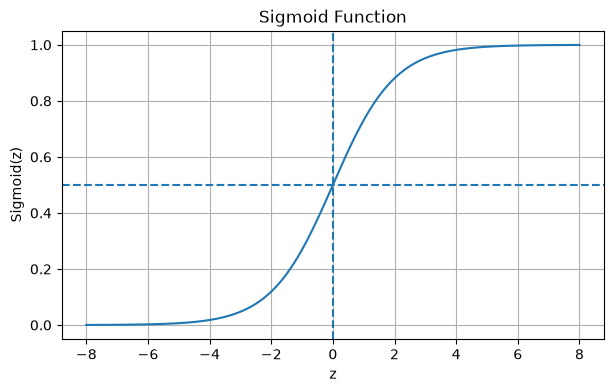

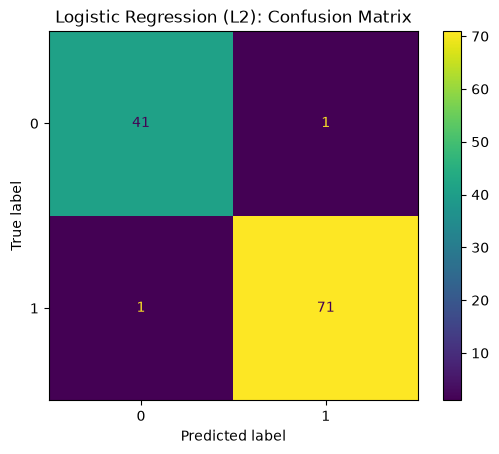

In [4]:
z = np.linspace(-8, 8, 300)
plt.figure(figsize=(7, 4))
plt.plot(z, sigmoid(z))
plt.axhline(0.5, linestyle="--")
plt.axvline(0, linestyle="--")
plt.xlabel("z")
plt.ylabel("Sigmoid(z)")
plt.title("Sigmoid Function")
plt.grid(True)
plt.show()

# Confusion matrix for the L2 model
ConfusionMatrixDisplay.from_estimator(log_models["L2 (Ridge-style)"], X_test, y_test)
plt.title("Logistic Regression (L2): Confusion Matrix")
plt.show()

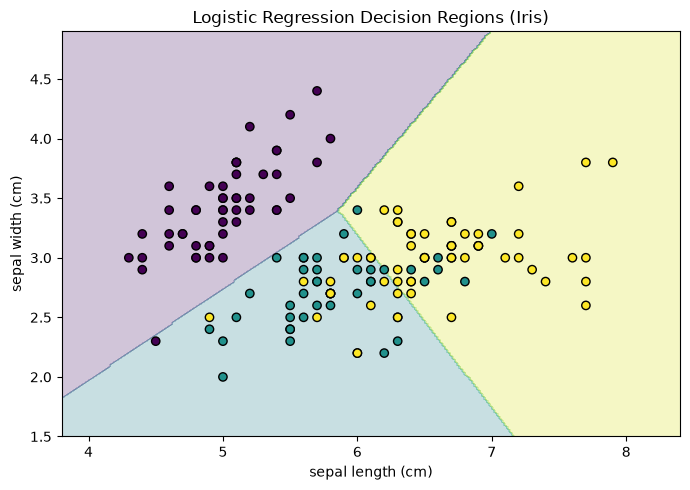

In [5]:
# Decision boundary visualization on two Iris features (three-class example)
iris = load_iris()
X2, y2 = iris.data[:, :2], iris.target
X_train2, X_test2, y_train2, y_test2 = train_test_split(
    X2, y2, test_size=0.2, random_state=42, stratify=y2
)
boundary_model = make_pipeline(StandardScaler(), LogisticRegression(max_iter=10000))
boundary_model.fit(X_train2, y_train2)

x_min, x_max = X2[:, 0].min() - 0.5, X2[:, 0].max() + 0.5
y_min, y_max = X2[:, 1].min() - 0.5, X2[:, 1].max() + 0.5
xx, yy = np.meshgrid(np.linspace(x_min, x_max, 250), np.linspace(y_min, y_max, 250))
grid = np.c_[xx.ravel(), yy.ravel()]
zz = boundary_model.predict(grid).reshape(xx.shape)

plt.figure(figsize=(7, 5))
plt.contourf(xx, yy, zz, alpha=0.25)
plt.scatter(X2[:, 0], X2[:, 1], c=y2, edgecolor="k")
plt.xlabel(iris.feature_names[0])
plt.ylabel(iris.feature_names[1])
plt.title("Logistic Regression Decision Regions (Iris)")
plt.tight_layout()
plt.show()